# BÀI 2: PHÂN LOẠI ĐỐI TƯỢNG DỰA TRÊN ĐẶC TRƯNG HÌNH DẠNG VÀ HOG
**Mục tiêu:** Thực hành phân ngưỡng Otsu, phát hiện biên Canny, xác định Contour; trích chọn 6 nhóm đặc trưng hình học ($A, P, W, H, AR, C, ED$) và đặc trưng HOG; so sánh hiệu năng của **KNN, SVM và Random Forest** trên bộ dữ liệu 3 lớp đối tượng: **Hình tròn (`circle`), Hình vuông (`square`), Hình tam giác (`triangle`)**.

## Yêu cầu 1: Tiền xử lý và Phân đoạn ảnh
Quy trình xử lý từng ảnh: `Ảnh gốc` → `Grayscale` → `Gaussian Blur (5×5)` → `Threshold / Otsu (tự động chuẩn hóa cực tính nền)` → `Phát hiện biên Canny` → `Tìm Contour lớn nhất & Khung bao`.

Đã hiển thị chuỗi bước tiền xử lý và phân đoạn cho 3 lớp: circle, square, triangle.


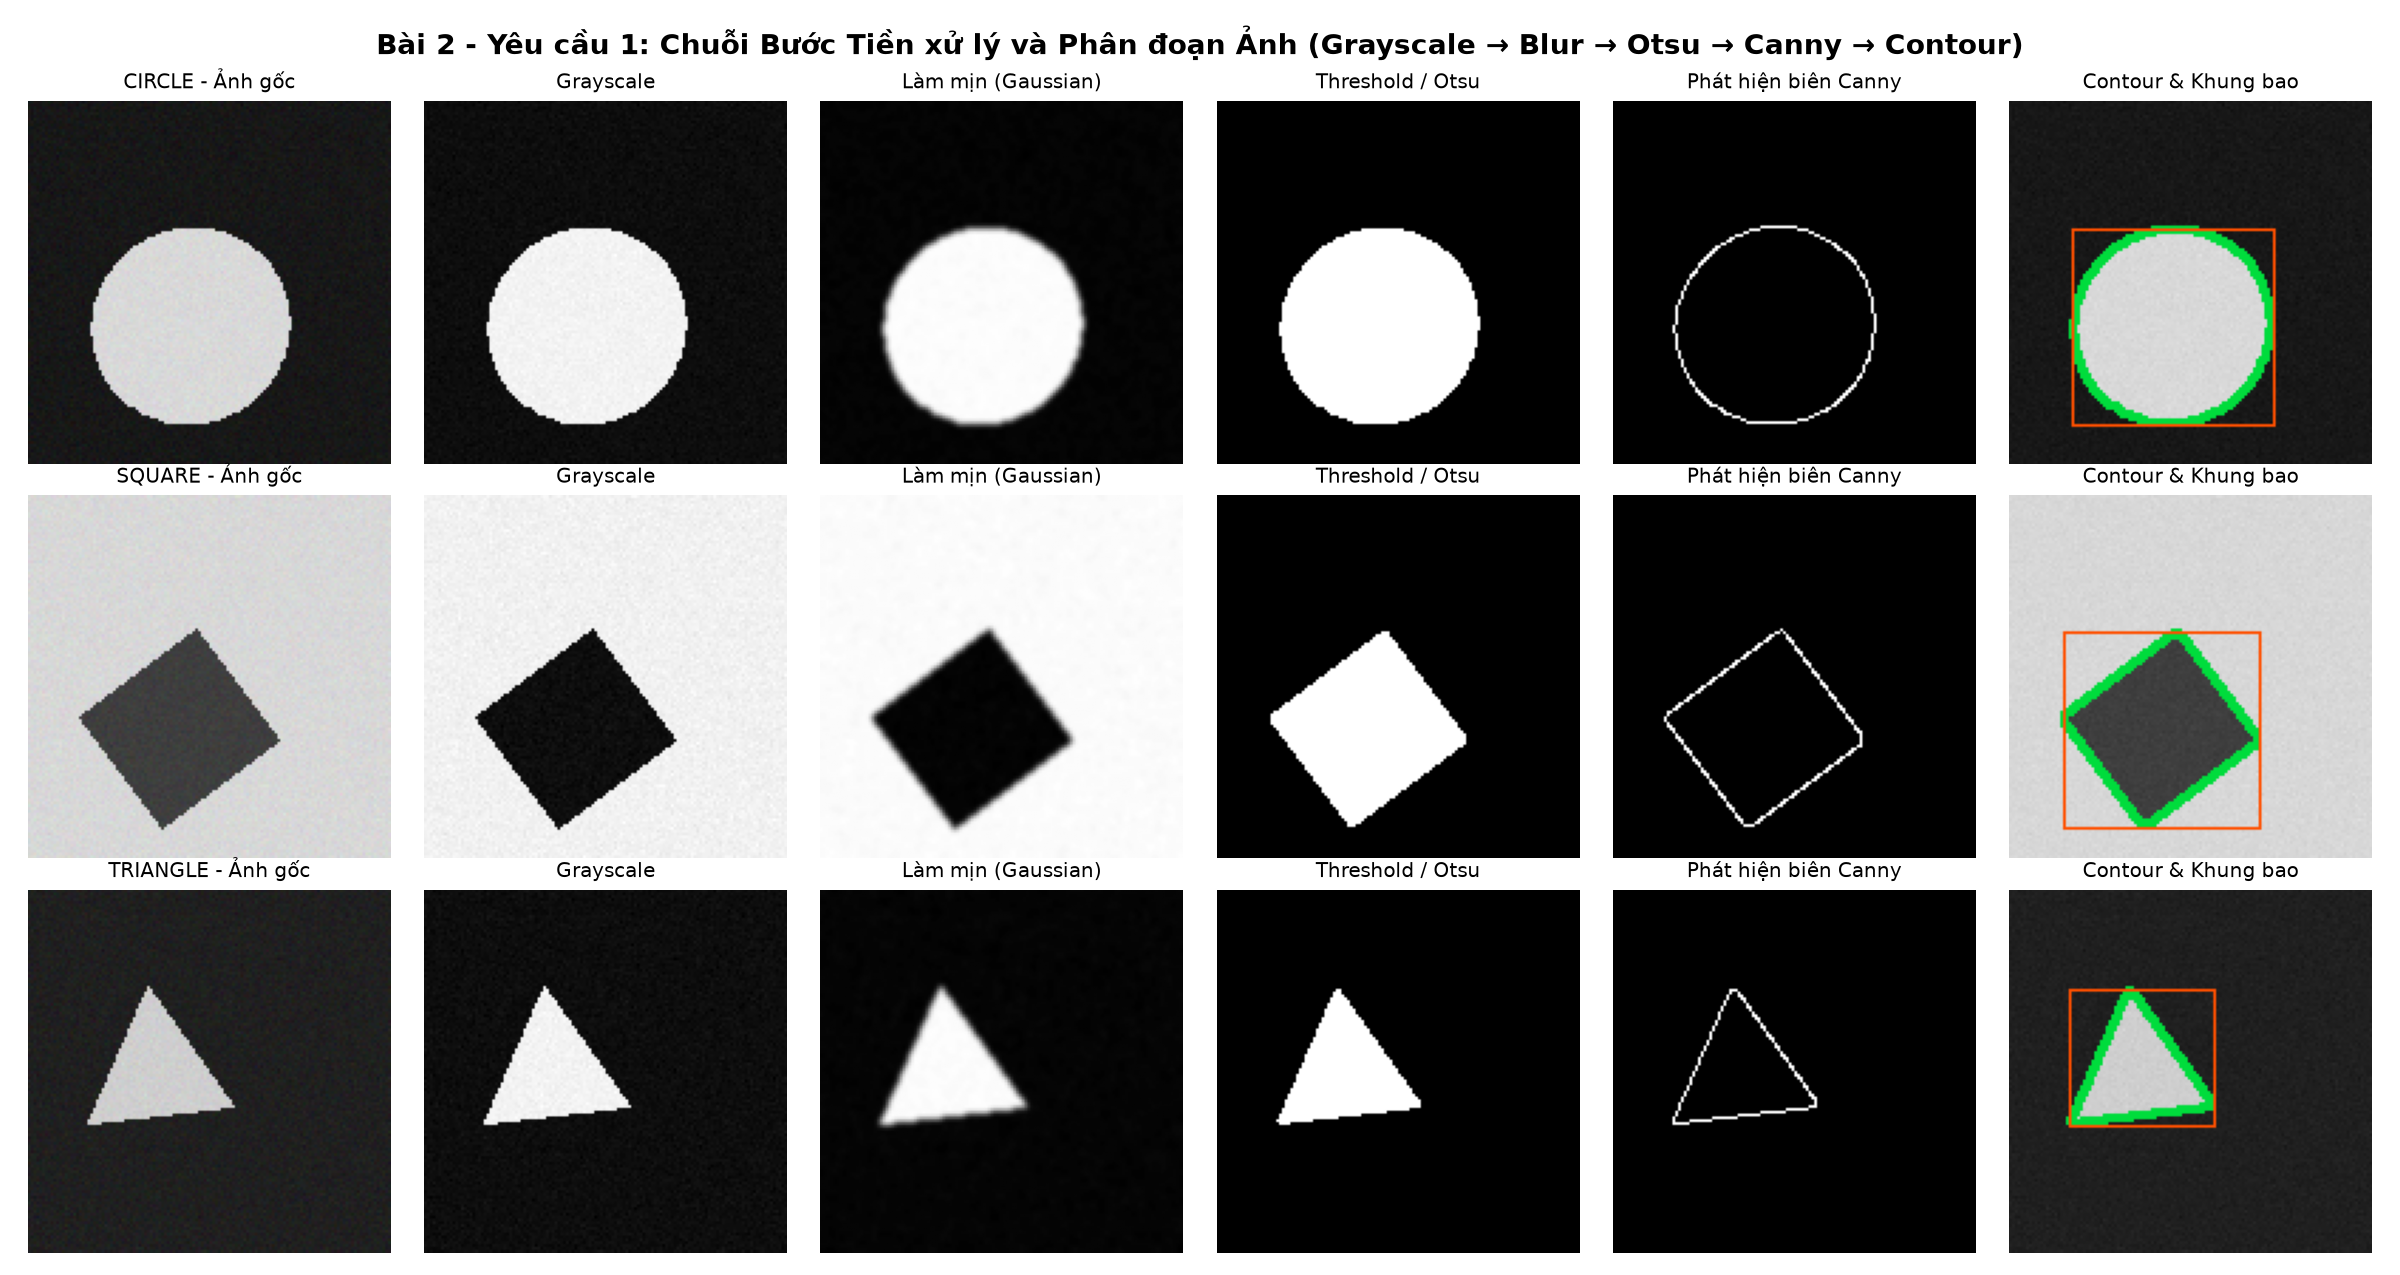

In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread("outputs/bai2/fig1_segmentation_steps.png")
plt.figure(figsize=(16, 8.5))
plt.imshow(img)
plt.axis("off")
plt.show()

## Yêu cầu 2 & 3: Trích chọn Đặc trưng Hình dạng (7 chiều) và Đặc trưng HOG (1.764 chiều)
- **Đặc trưng hình dạng (7 giá trị):** Diện tích $A$, Chu vi $P$, Kích thước $W, H$, Tỷ lệ khung bao $AR = W/H$, Độ tròn $C = 4\pi A / P^2$, Mật độ biên $ED$.
- **Đặc trưng HOG:** Ảnh chuẩn hóa về `64×64`, `cell_size=(8,8)`, `block_size=(16,16)`, `block_stride=(8,8)`, `nbins=9` → Số chiều vector HOG = $7 \times 7 \times 4 \times 9 = 1.764$ chiều (gấp **252 lần** số chiều vector hình dạng).

Tổng số mẫu: 450 ảnh (150 ảnh/lớp cho circle, square, triangle)

=== MẪU BẢNG ĐẶC TRƯNG HÌNH DẠNG (7 CHIỀU) ===
   label  Area_A  Perimeter_P  Width_W  Height_H  AspectRatio_AR  Circularity_C  EdgeDensity_ED
  circle  1555.0   149.539104     51.0      41.0        1.243902       0.873838        0.066475
  circle  3741.0   229.137083     71.0      69.0        1.028986       0.895379        0.044295
  circle  1196.5   129.639609     39.0      41.0        0.951220       0.894638        0.072545
  square  5524.5   299.002087    102.0      99.0        1.030303       0.776523        0.034165
  square  2494.0   206.391912     69.0      69.0        1.000000       0.735734        0.048519
  square  4484.0   276.617309     93.0      93.0        1.000000       0.736405        0.036767
triangle   681.0   109.740114     31.0      37.0        0.837838       0.710602        0.082825
triangle  1161.0   161.195957     51.0      48.0        1.062500       0.561479        0.064134
triangle   644.0   118.0

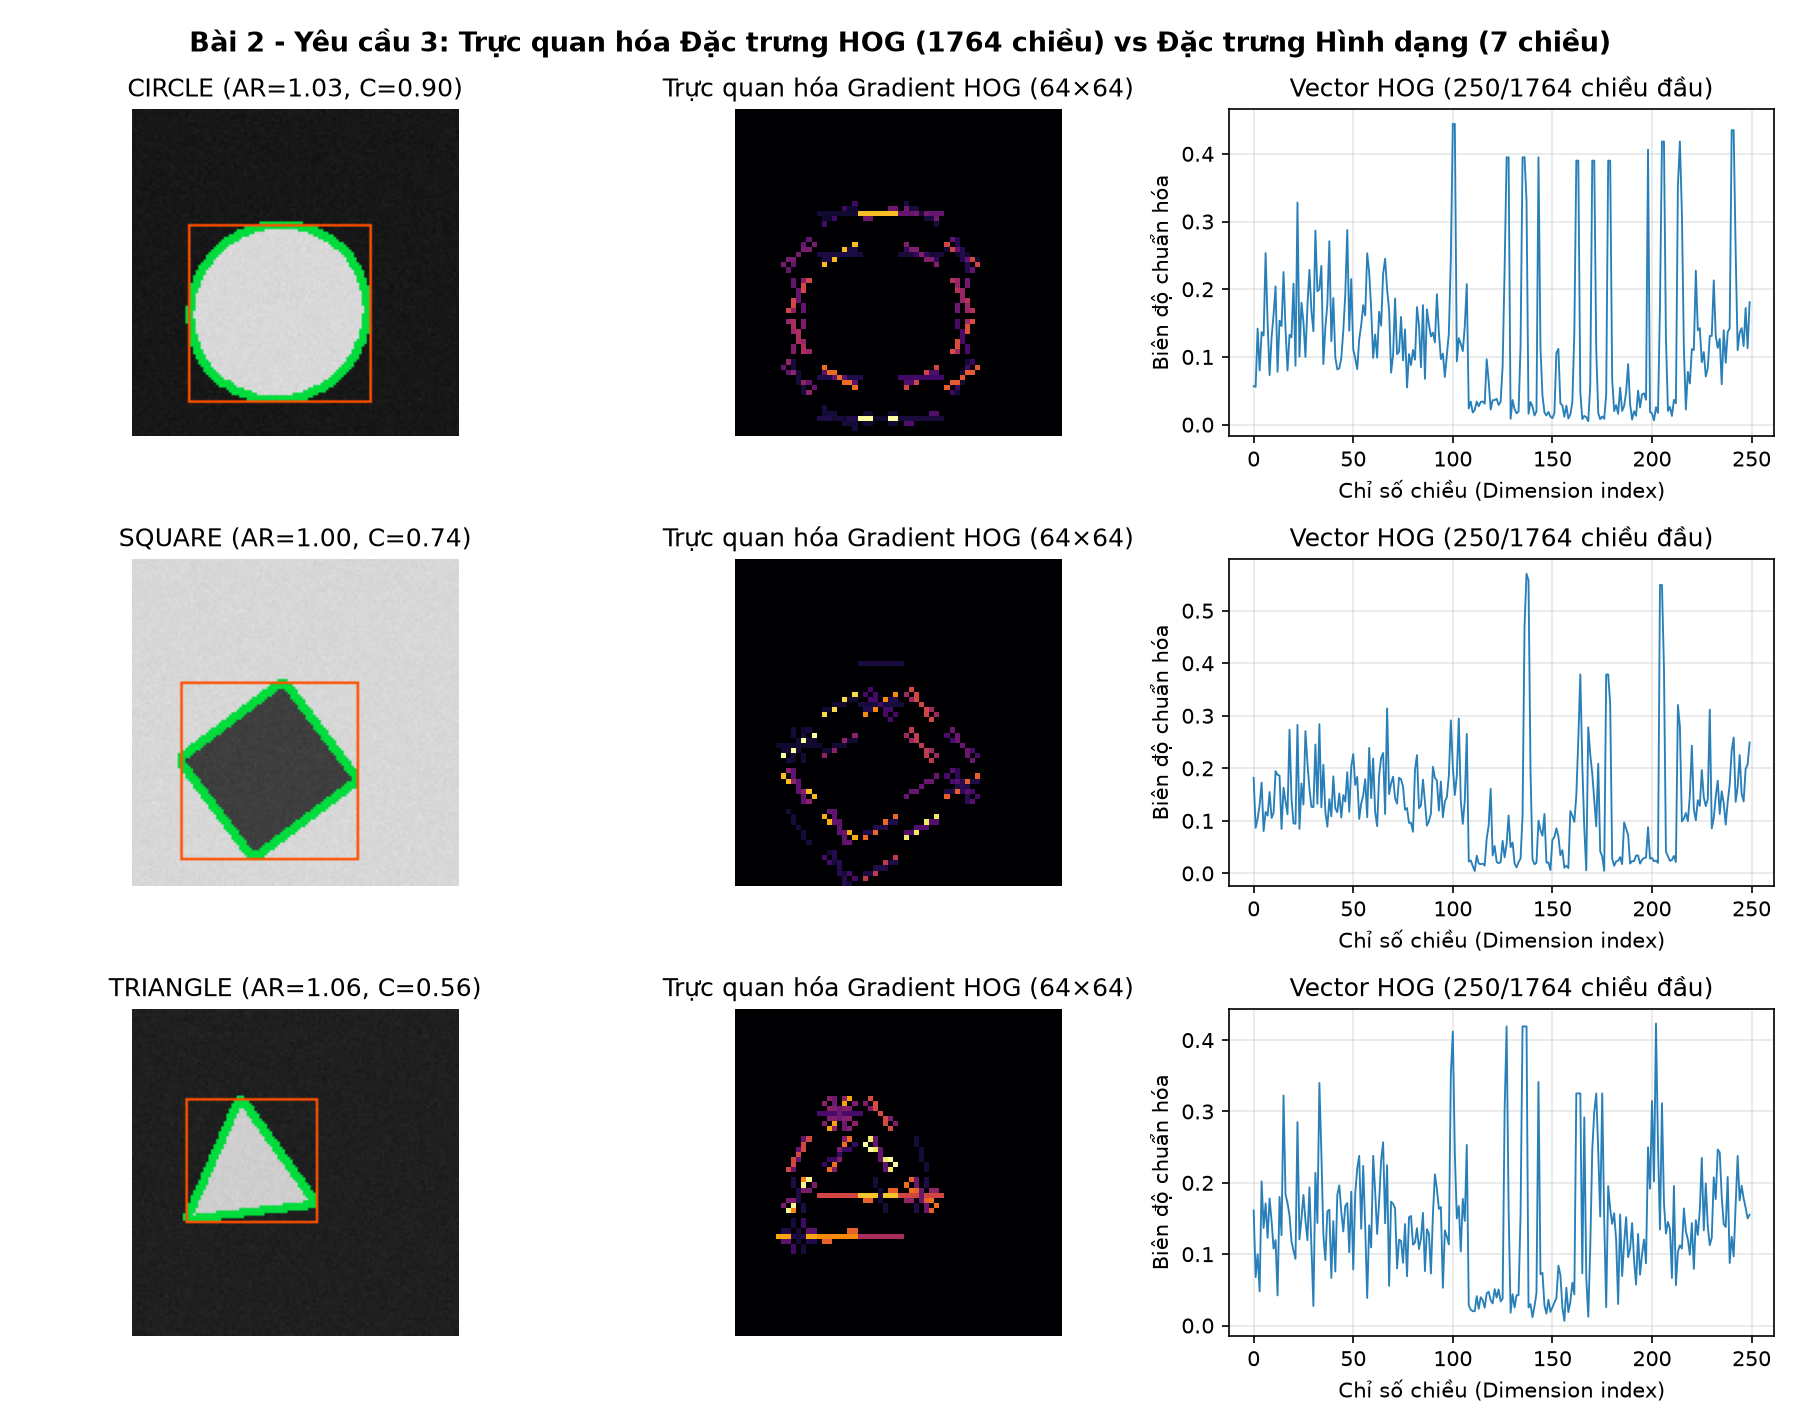

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

df_shape = pd.read_csv("outputs/bai2/bai2_shape_features.csv")
shape_cols = ["label", "Area_A", "Perimeter_P", "Width_W", "Height_H", "AspectRatio_AR", "Circularity_C", "EdgeDensity_ED"]
print(df_shape[shape_cols].groupby("label").head(3).to_string(index=False))
print("\n=== TRUNG BÌNH ĐẶC TRƯNG HÌNH DẠNG THEO LỚP ===")
print(df_shape.groupby("label")[shape_cols[1:]].mean().round(3).to_string())

img = mpimg.imread("outputs/bai2/fig2_hog_visualization.png")
plt.figure(figsize=(12, 9.5))
plt.imshow(img)
plt.axis("off")
plt.show()

## Yêu cầu 4 & 5: Phân loại, So sánh KNN / SVM / Random Forest trên 3 Trường hợp Đặc trưng

=== BẢNG SO SÁNH 9 TỔ HỢP (3 TẬP ĐẶC TRƯNG × 3 MÔ HÌNH) ===
        Feature_Set  Num_Dims         Model  Accuracy  Precision  Recall  F1-score
    Shape Only (7D)         7           KNN    1.0000     1.0000  1.0000    1.0000
    Shape Only (7D)         7           SVM    1.0000     1.0000  1.0000    1.0000
    Shape Only (7D)         7 Random Forest    1.0000     1.0000  1.0000    1.0000
   HOG Only (1764D)      1764           KNN    0.9111     0.9244  0.9111    0.9101
   HOG Only (1764D)      1764           SVM    0.9222     0.9250  0.9222    0.9221
   HOG Only (1764D)      1764 Random Forest    0.8222     0.8361  0.8222    0.8207
Shape + HOG (1771D)      1771           KNN    0.9222     0.9369  0.9222    0.9211
Shape + HOG (1771D)      1771           SVM    0.9222     0.9250  0.9222    0.9221
Shape + HOG (1771D)      1771 Random Forest    0.8667     0.8747  0.8667    0.8639


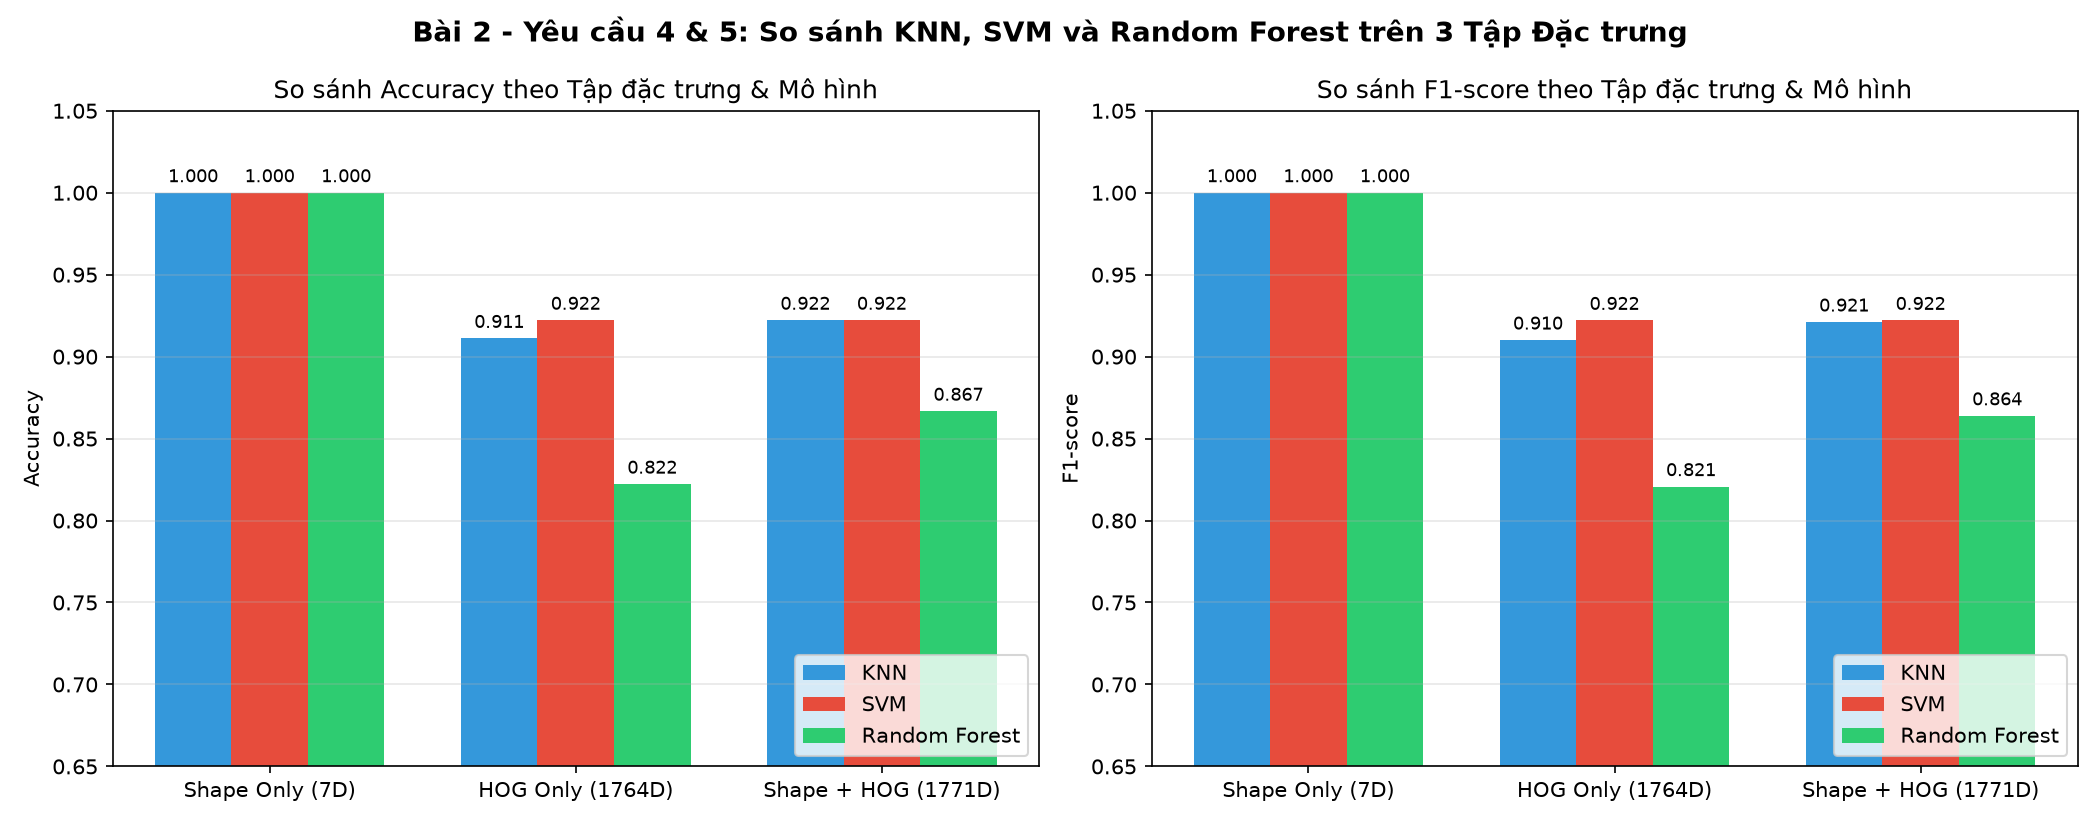

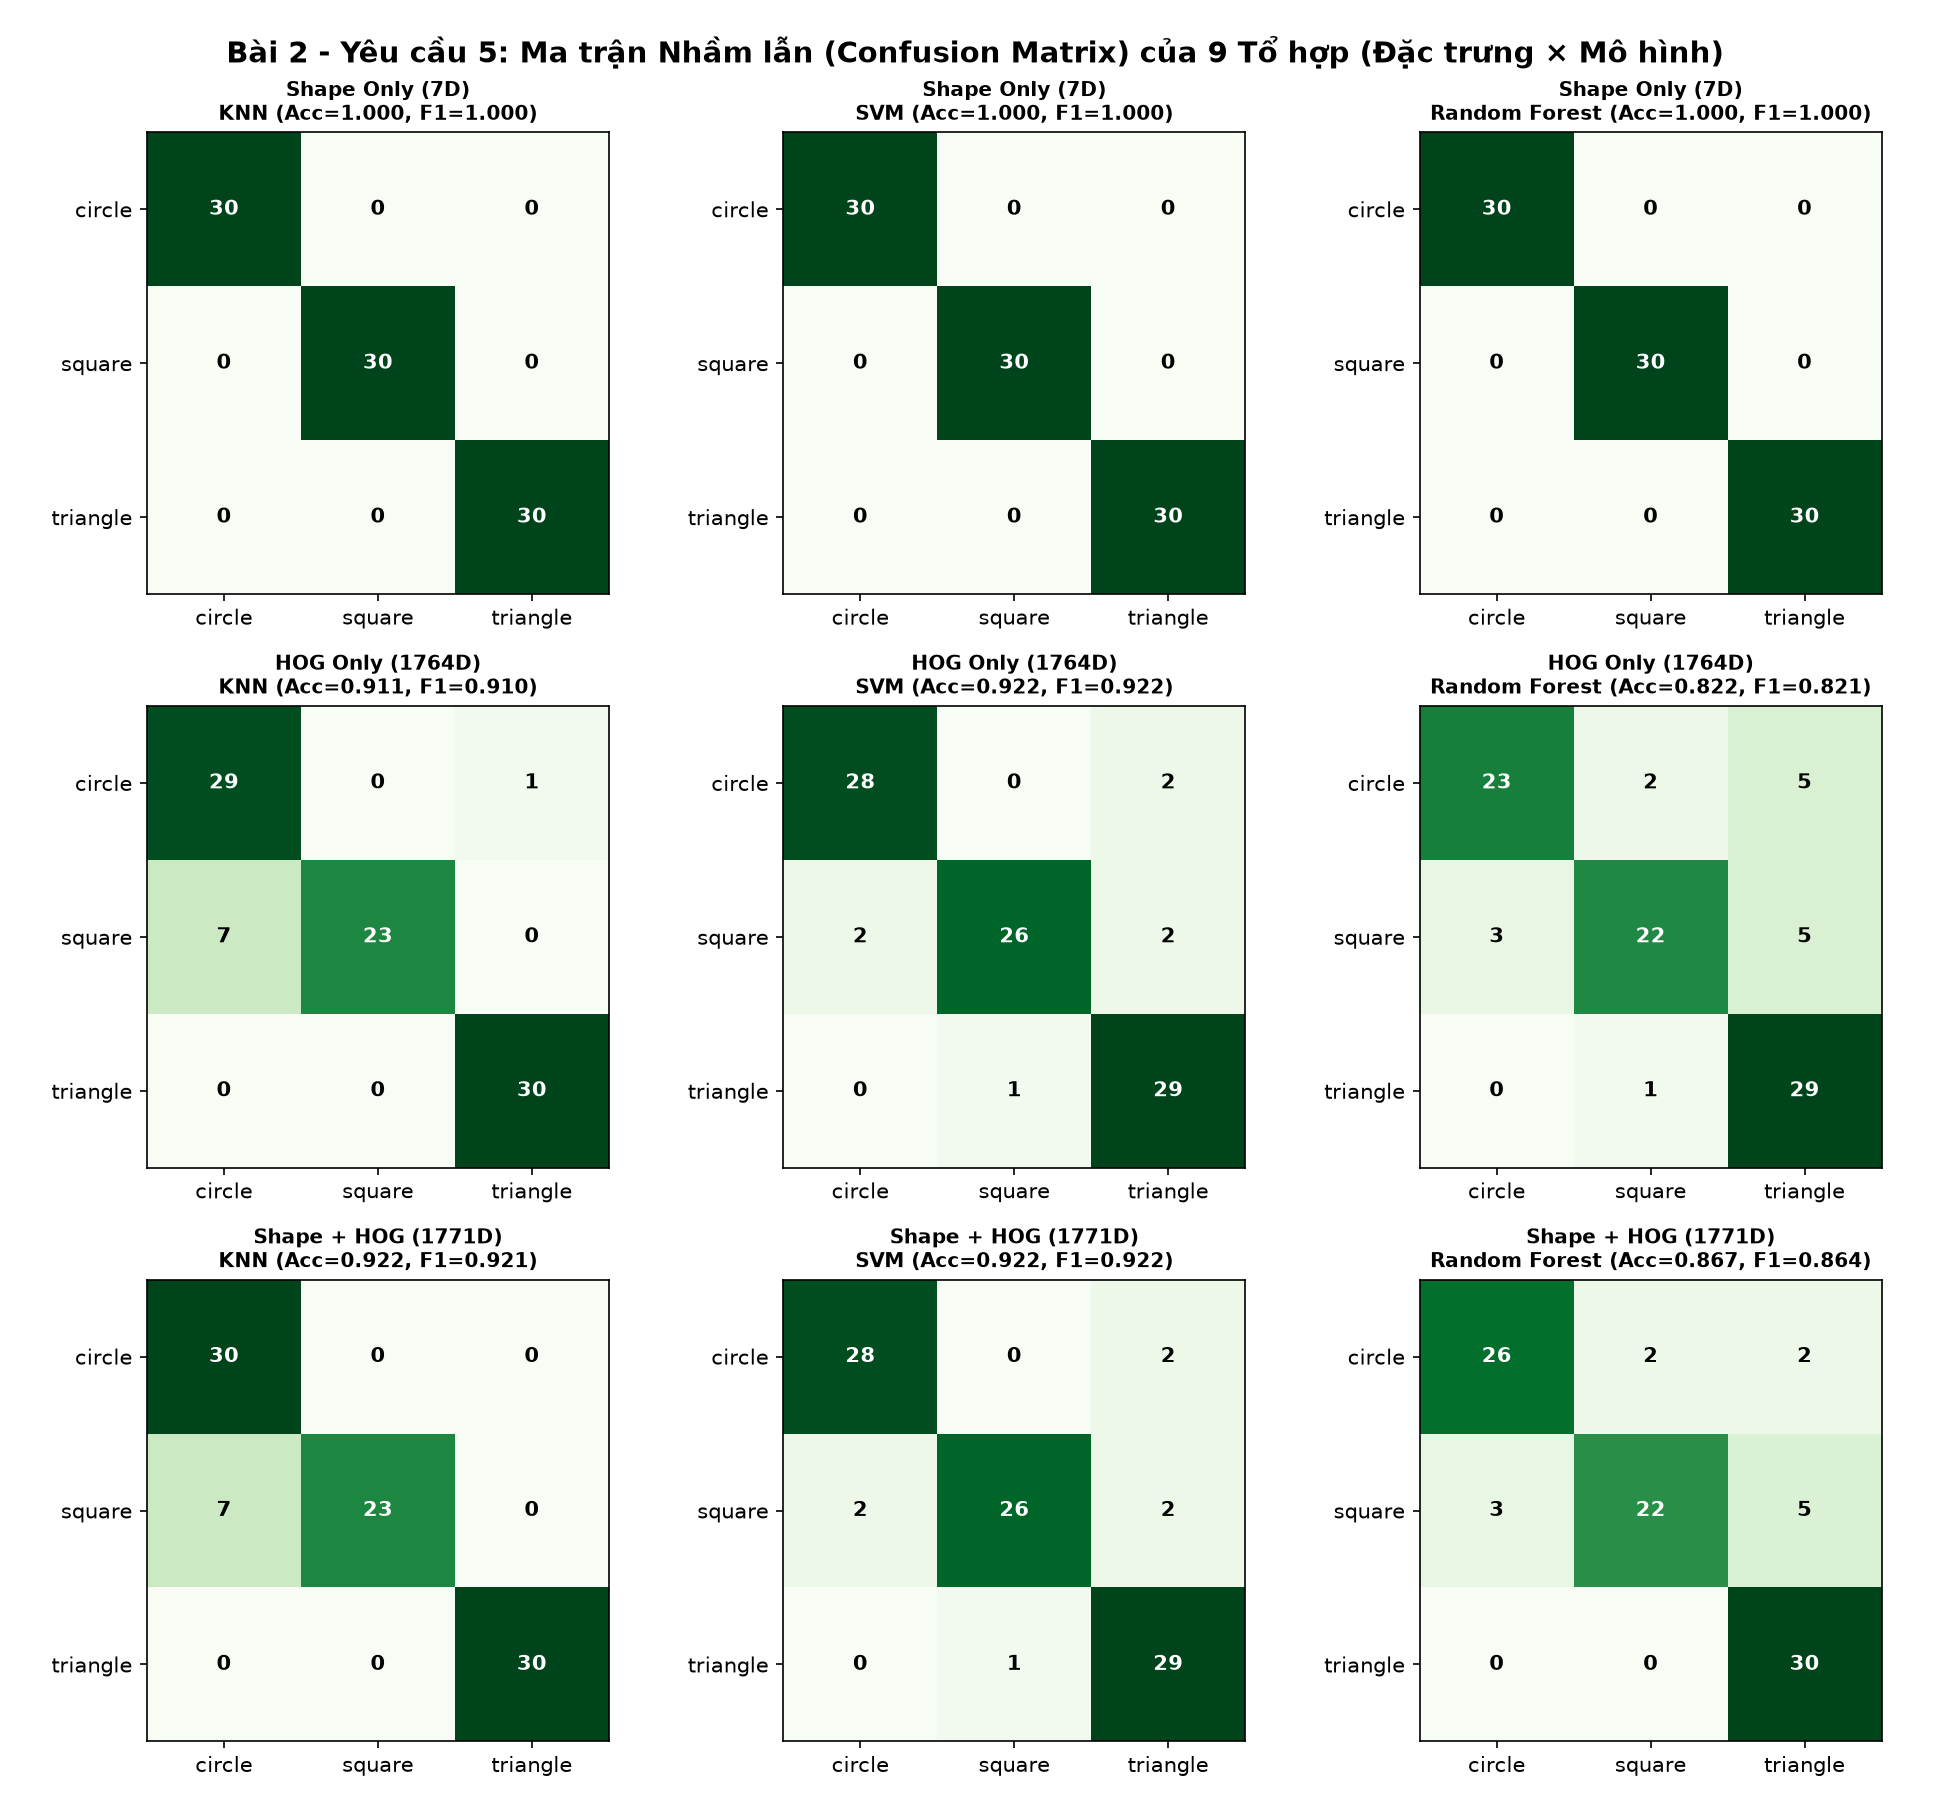

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

df_metrics = pd.read_csv("outputs/bai2/bai2_metrics.csv")
print("=== BẢNG SO SÁNH 9 TỔ HỢP (3 TẬP ĐẶC TRƯNG × 3 MÔ HÌNH) ===")
print(df_metrics.to_string(index=False))

for fig_file in ["outputs/bai2/fig3_model_comparison.png", "outputs/bai2/fig4_confusion_matrices.png"]:
    img = mpimg.imread(fig_file)
    plt.figure(figsize=(13, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

## Dự đoán trên Ảnh Mới & Phân tích Ví dụ Phân loại Sai

=== DỰ ĐOÁN TRÊN ẢNH MỚI (UNSEEN IMAGES) ===
true_label Pred_Shape_RF Pred_HOG_SVM Pred_Combined_SVM
    circle        circle       circle            circle
    circle        circle       circle            circle
    circle        circle       circle            circle
    circle        circle       circle            circle
    square        square       square            square
    square        square       square            square
    square        square       circle            circle
    square        square       square            square
  triangle      triangle     triangle          triangle
  triangle      triangle     triangle          triangle
  triangle      triangle     triangle          triangle
  triangle      triangle     triangle          triangle

=== THỐNG KÊ CÁC MẪU PHÂN LOẠI SAI TRÊN TẬP TEST (57 lượt) ===
     Feature_Set Model true_label pred_label  AspectRatio_AR  Circularity_C
HOG Only (1764D)   KNN     square     circle        1.085106       0.708316
HOG Only (1

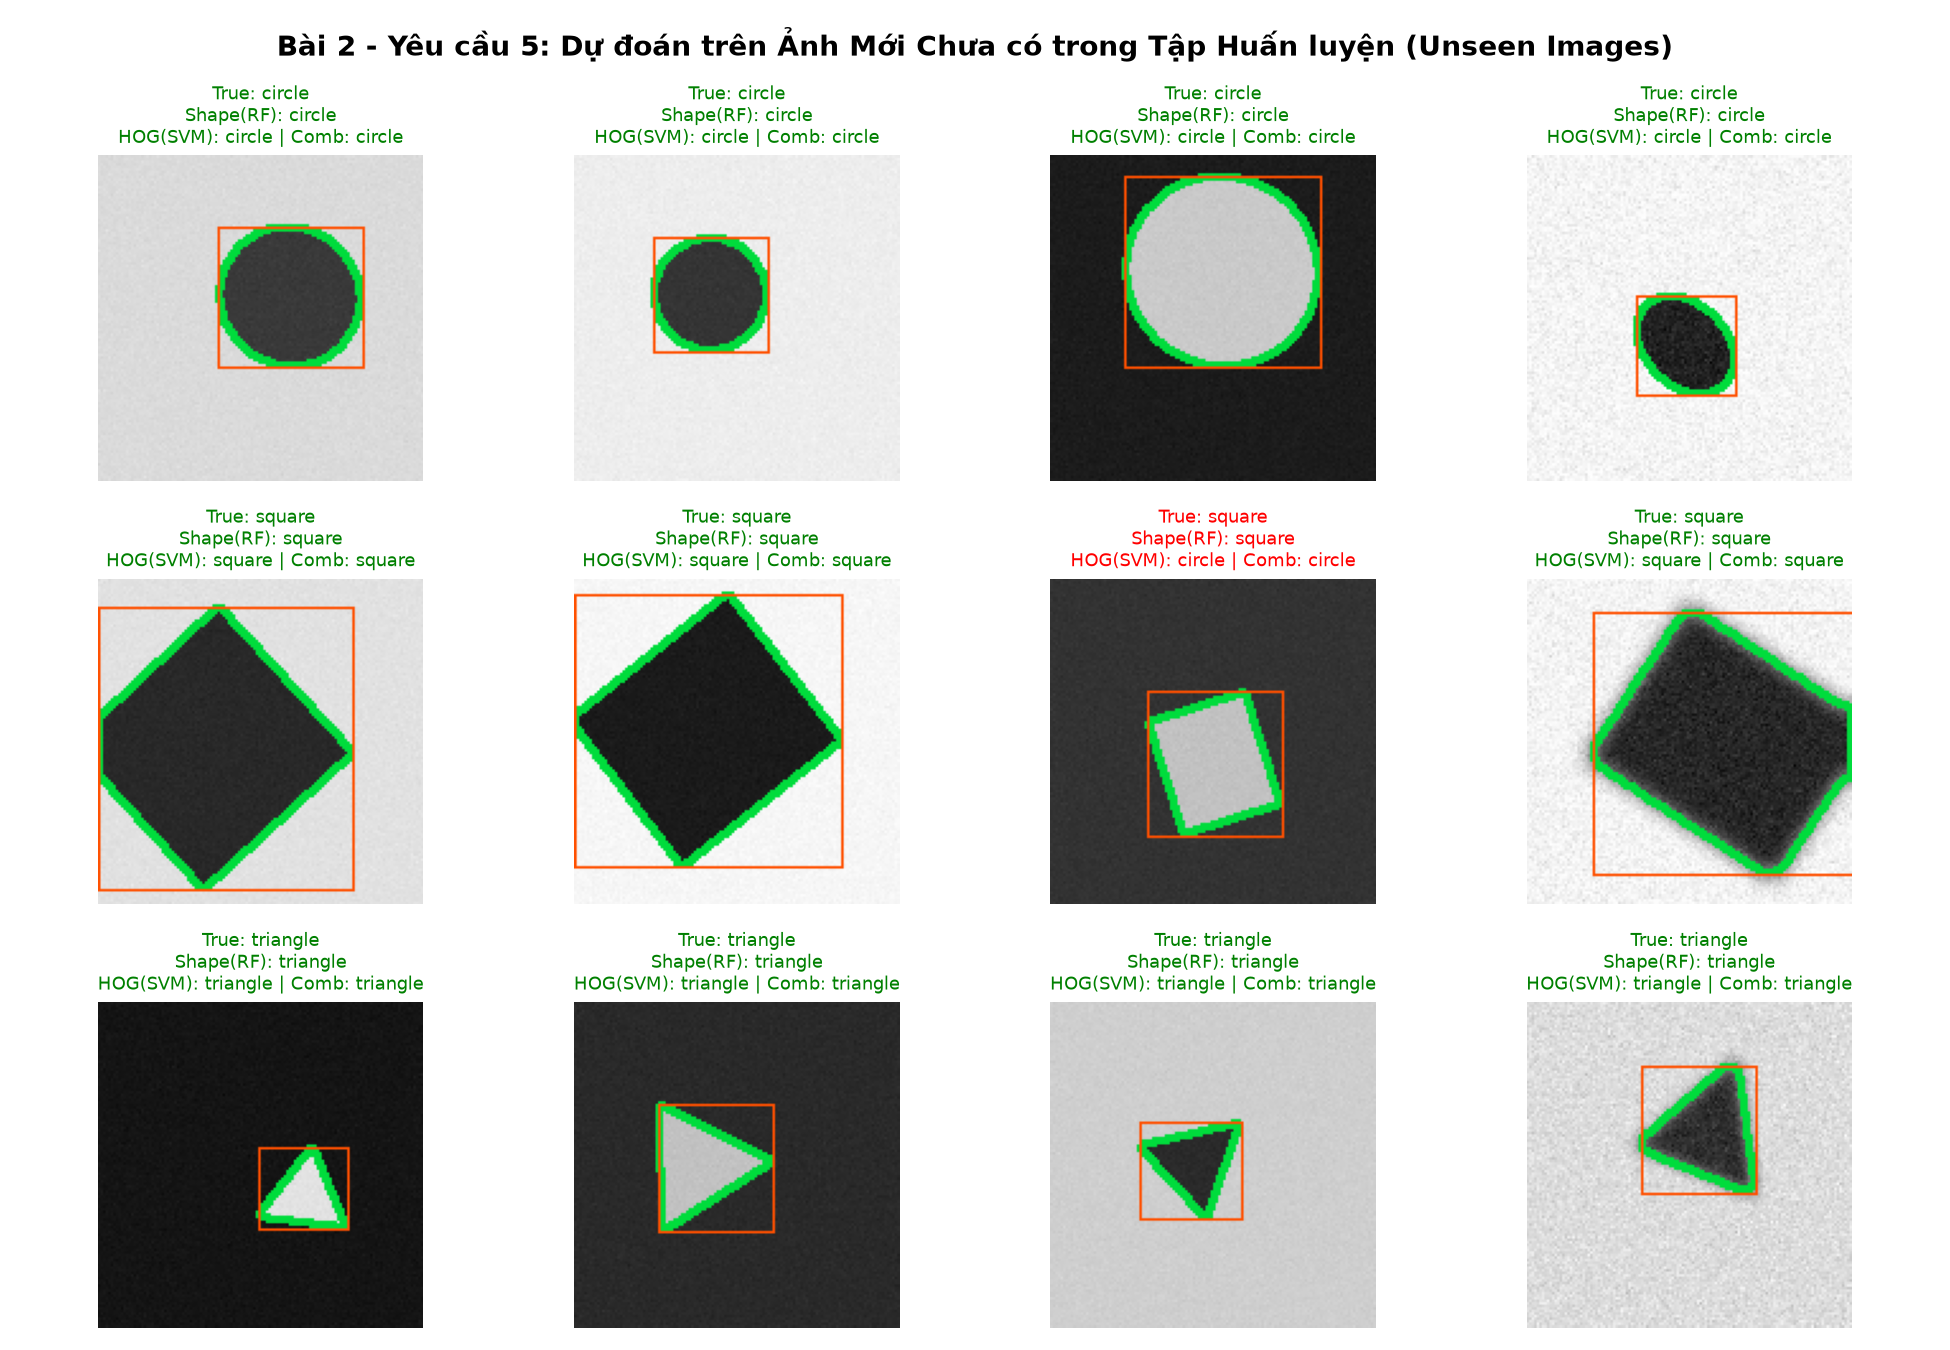

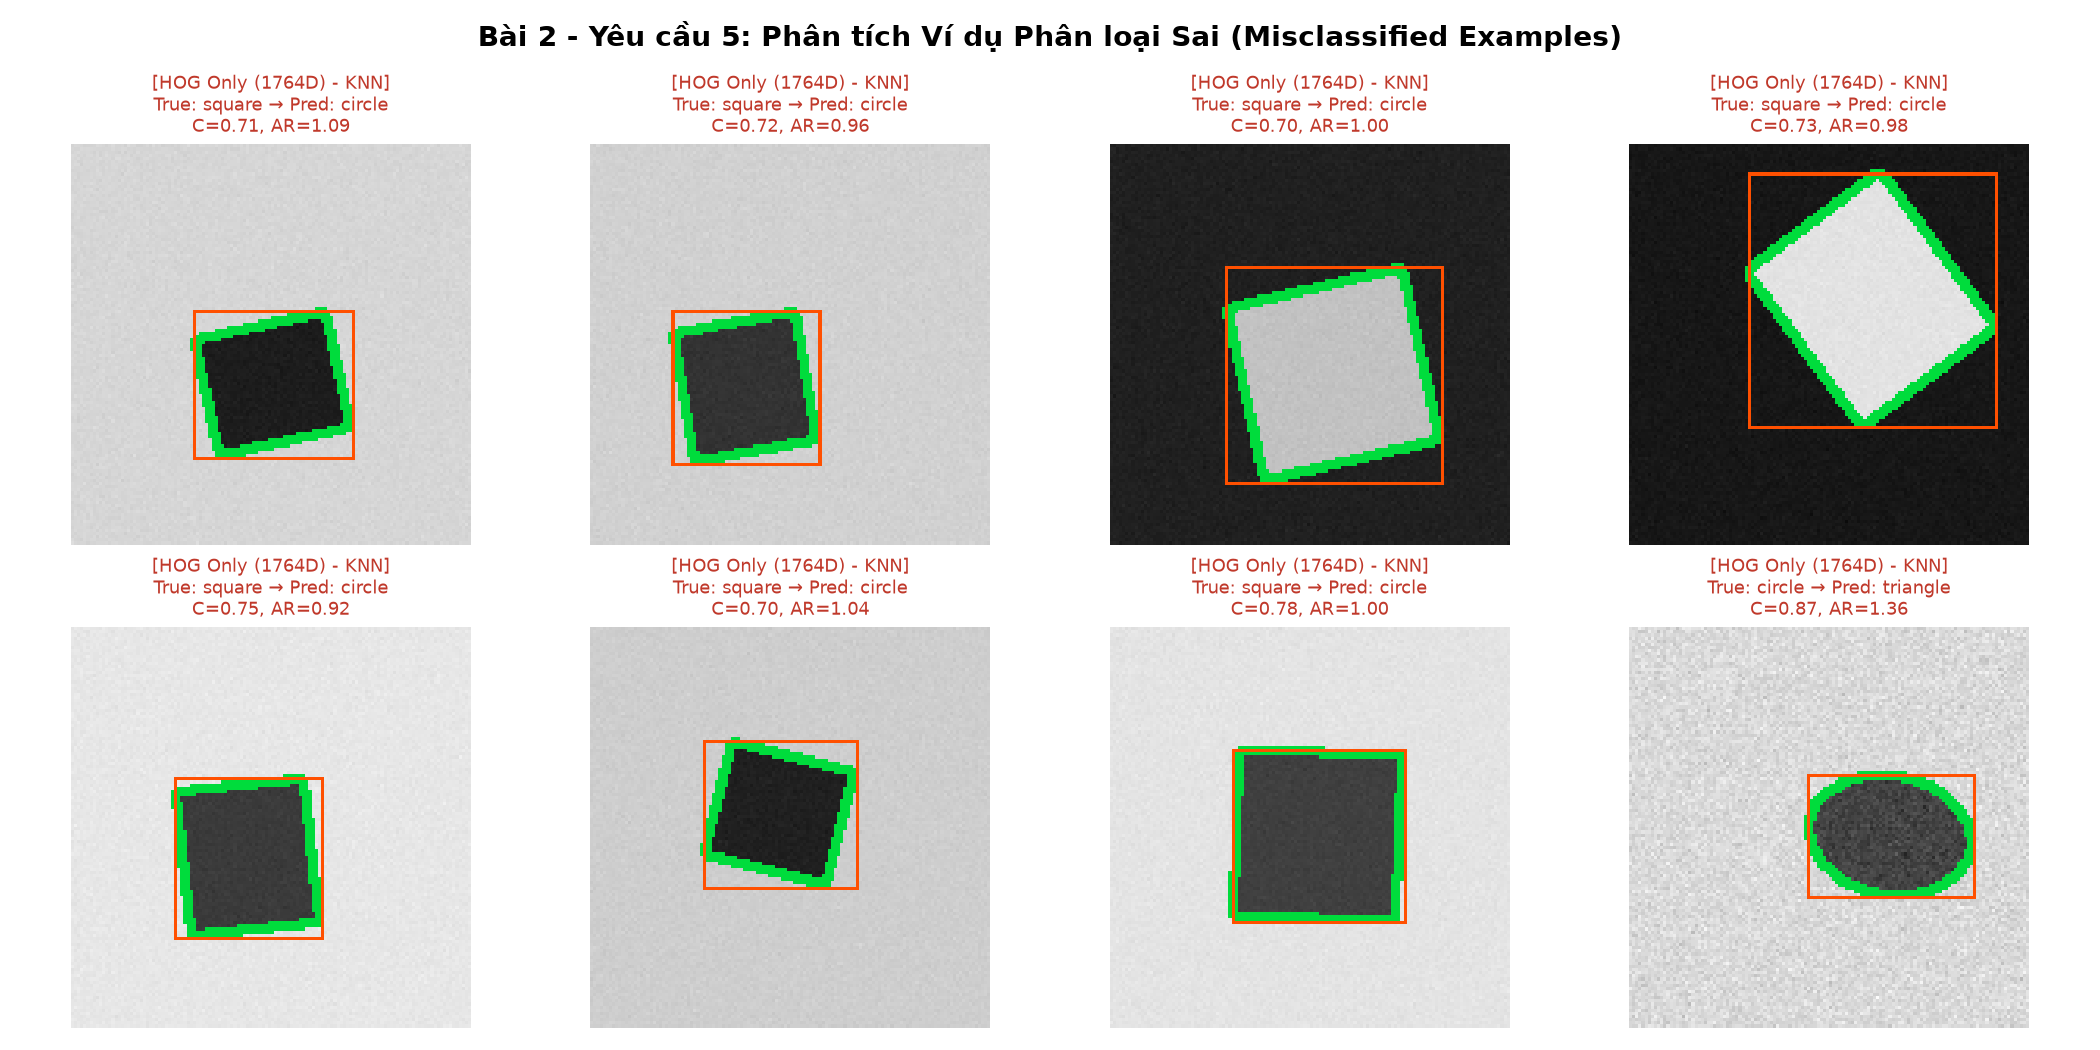

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

df_unseen = pd.read_csv("outputs/bai2/bai2_unseen_predictions.csv")
df_mis = pd.read_csv("outputs/bai2/bai2_misclassified.csv")
print(df_unseen[["true_label", "Pred_Shape_RF", "Pred_HOG_SVM", "Pred_Combined_SVM"]].to_string(index=False))
print("\n=== MẪU PHÂN LOẠI SAI TRÊN TẬP TEST ===")
print(df_mis[["Feature_Set", "Model", "true_label", "pred_label", "AspectRatio_AR", "Circularity_C"]].head(10).to_string(index=False))

for fig_file in ["outputs/bai2/fig5_unseen_predictions.png", "outputs/bai2/fig6_misclassified_analysis.png"]:
    img = mpimg.imread(fig_file)
    plt.figure(figsize=(13, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.show()